In [1]:
%pip install pandas matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
customers = pd.read_csv("customers.csv")

orders = pd.read_csv("orders.csv")

print("Customers Data:")
display(customers.head())

print("Orders Data:")
display(orders.head())

Customers Data:


,customer_id,customer_name,city
0,C001,Aman,Lucknow
1,C002,Ravi,Delhi
2,C003,Priya,Patna
3,C004,Neha,Lucknow
4,C005,Rahul,Delhi


Orders Data:


,order_id,customer_id,order_amount
0,O101,C001,1200
1,O102,C002,2500
2,O103,C001,800
3,O104,C003,1500
4,O105,C004,3200


In [4]:
df = pd.merge(
    orders,
    customers,
    on="customer_id",
    how="left"
)

print("Merged Data:")
display(df.head())

print("Total Rows:", len(df))

Merged Data:


,order_id,customer_id,order_amount,customer_name,city
0,O101,C001,1200,Aman,Lucknow
1,O102,C002,2500,Ravi,Delhi
2,O103,C001,800,Aman,Lucknow
3,O104,C003,1500,Priya,Patna
4,O105,C004,3200,Neha,Lucknow


Total Rows: 15


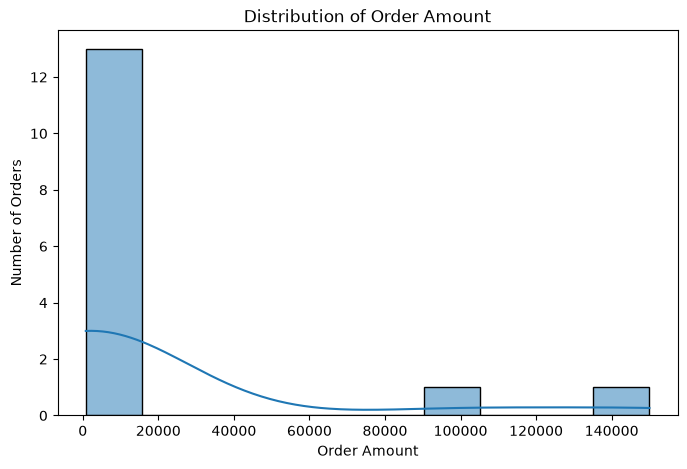

In [5]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="order_amount",
    bins=10,
    kde=True
)

plt.title("Distribution of Order Amount")
plt.xlabel("Order Amount")
plt.ylabel("Number of Orders")

plt.show()

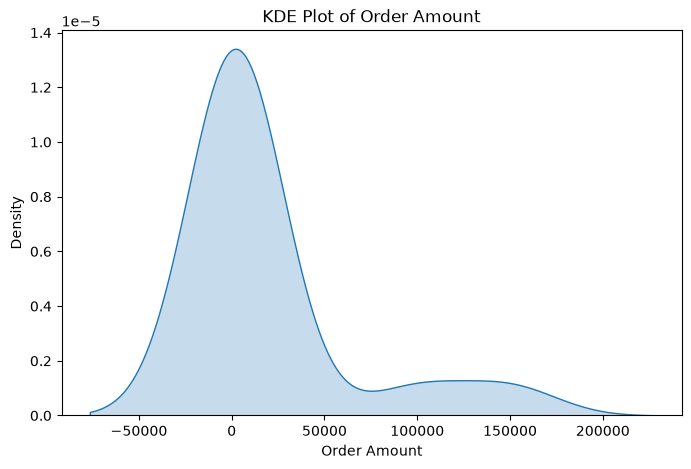

In [6]:
plt.figure(figsize=(8, 5))

sns.kdeplot(
    data=df,
    x="order_amount",
    fill=True
)

plt.title("KDE Plot of Order Amount")
plt.xlabel("Order Amount")

plt.show()

In [7]:
city_revenue = df.groupby("city")["order_amount"].sum()

city_revenue = city_revenue.reset_index()

city_revenue.columns = ["City", "Total Revenue"]

display(city_revenue)

,City,Total Revenue
0,Delhi,6900
1,Jaipur,2100
2,Lucknow,106299
3,Mumbai,154500
4,Patna,7600


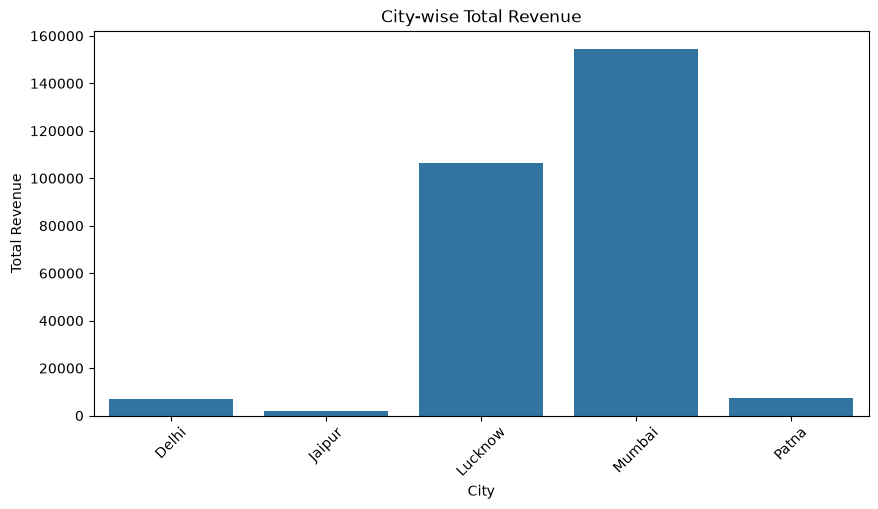

In [8]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=city_revenue,
    x="City",
    y="Total Revenue"
)

plt.title("City-wise Total Revenue")
plt.xlabel("City")
plt.ylabel("Total Revenue")

plt.xticks(rotation=45)

plt.show()

In [9]:
city_orders = df.groupby("city")["order_id"].count()

city_orders = city_orders.reset_index()

city_orders.columns = ["City", "Total Orders"]

display(city_orders)

,City,Total Orders
0,Delhi,3
1,Jaipur,1
2,Lucknow,5
3,Mumbai,3
4,Patna,3


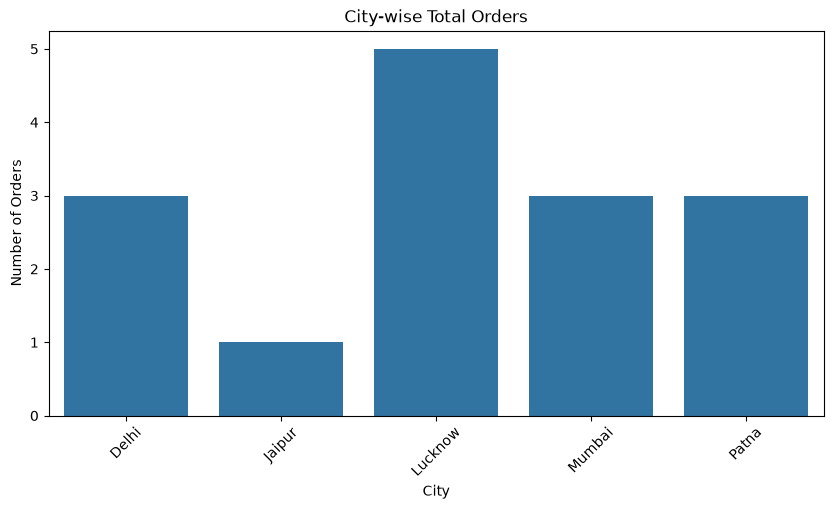

In [10]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=city_orders,
    x="City",
    y="Total Orders"
)

plt.title("City-wise Total Orders")
plt.xlabel("City")
plt.ylabel("Number of Orders")

plt.xticks(rotation=45)

plt.show()

In [11]:
customer_metrics = df.groupby("customer_id").agg(
    total_orders=("order_id", "count"),
    total_spending=("order_amount", "sum"),
    average_order_value=("order_amount", "mean")
)

display(customer_metrics)

,total_orders,total_spending,average_order_value
customer_id,,,
C001,2,2000,1000.0
C002,2,6000,3000.0
C003,2,3100,1550.0
C004,2,103199,51599.5
C005,1,900,900.0
C006,1,4500,4500.0
C007,2,151800,75900.0
C008,1,1100,1100.0
C009,1,2700,2700.0


In [12]:
correlation_matrix = customer_metrics.corr()

display(correlation_matrix)

,total_orders,total_spending,average_order_value
total_orders,1.000000,0.498917,0.481784
total_spending,0.498917,1.000000,0.999644
average_order_value,0.481784,0.999644,1.000000


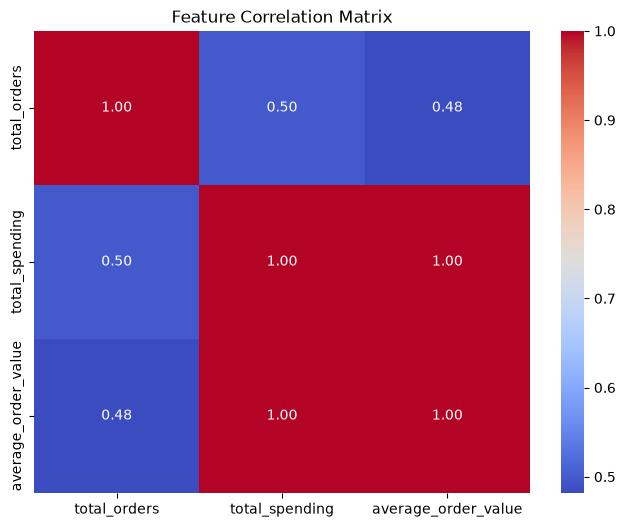

In [13]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Matrix")

plt.show()